# Banking Transaction Anomaly & Customer Behaviour EDA

**Industry:** IDFC FIRST Bank - Banking & Financial Services (BFSI)
**Organization:** Anudip Foundation | **Course:** AIML

This notebook walks through the full analysis pipeline. The logic lives in the
reusable modules under `Python/`; here we load them and run each stage so the
results are visible end-to-end.

Development cycle: *Industry Selection -> Problem Identification -> Dataset
Collection -> Data Cleaning -> Data Transformation -> Data Analysis -> Data
Visualization -> Insights -> Recommendations.*


In [1]:
# --- Environment setup -----------------------------------------------------
from pathlib import Path
import sys, os

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "Python").exists() else cwd.parent
sys.path.insert(0, str(PROJECT_ROOT / "Python"))
os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)

Project root: /Users/harish/Projects/BankingAnamolyDetection


## 1. Data Loading

We first make sure the raw dataset exists locally (downloading it if needed),
then load it unmodified so the cleaning step is fully auditable.

In [2]:
from data_loading import download_raw_dataset, load_raw_data, summarise

download_raw_dataset()
raw = load_raw_data()
summarise(raw)

[data_loading] Raw dataset already present -> /Users/harish/Projects/BankingAnamolyDetection/Dataset/raw_dataset.csv
[data_loading] Loaded raw dataset: 2512 rows x 16 columns

RAW DATASET SUMMARY
Shape            : 2512 rows x 16 columns
Columns          : ['TransactionID', 'AccountID', 'TransactionAmount', 'TransactionDate', 'TransactionType', 'Location', 'DeviceID', 'IP Address', 'MerchantID', 'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'PreviousTransactionDate']

--- Data types & missing values ---
                           dtype  non_null  missing  missing_%  unique
TransactionID                str      2512        0        0.0    2512
AccountID                    str      2512        0        0.0     495
TransactionAmount        float64      2512        0        0.0    2455
TransactionDate              str      2512        0        0.0    2512
TransactionType              str      2512        0        0.0       2
Locat

## 2. Data Cleaning & Data Transformation

Audit data quality, de-duplicate, enforce data types and parse timestamps, then
engineer the derived features used later.

In [3]:
from data_cleaning import build_cleaned_dataset

df = build_cleaned_dataset()

[data_loading] Raw dataset already present -> /Users/harish/Projects/BankingAnamolyDetection/Dataset/raw_dataset.csv
[data_loading] Loaded raw dataset: 2512 rows x 16 columns

DATA QUALITY AUDIT
rows                        : 2512
columns                     : 16
missing_values              : 0
duplicate_rows              : 0
duplicate_transaction_ids   : 0

Per-column missing values:
  none
negative_amounts            : 0
[data_cleaning] Dropped 0 duplicate row(s)
[data_cleaning] Normalised text columns: ['TransactionID', 'AccountID', 'TransactionType', 'Location', 'DeviceID', 'IP Address', 'MerchantID', 'Channel', 'CustomerOccupation']
[data_cleaning] Engineered 10 derived features
[data_cleaning] Saved cleaned dataset -> /Users/harish/Projects/BankingAnamolyDetection/Dataset/cleaned_dataset.csv

--- Cleaned dataset at a glance ---
Shape : 2512 rows x 26 columns
Columns added : ['TransactionYear', 'TransactionMonth', 'TransactionMonthName', 'TransactionDayOfWeek', 'TransactionDayName'

In [4]:
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,...,TransactionYear,TransactionMonth,TransactionMonthName,TransactionDayOfWeek,TransactionDayName,TransactionHour,IsWeekend,TimeSinceLastTransactionHours,AmountToBalanceRatio,SignedAmount
0,TX001313,AC00001,47.79,2023-09-15 17:00:20,Debit,Denver,D000649,59.12.96.11,M034,Branch,...,2023,9,Sep,4,Fri,17,False,NaN,0.02897,-47.79
1,TX002017,AC00001,212.97,2023-11-14 16:56:34,Debit,Atlanta,D000492,45.241.13.208,M003,Online,...,2023,11,Nov,1,Tue,16,False,1439.937,0.05094,-212.97
2,TX002121,AC00002,476.99,2023-01-10 16:00:32,Debit,San Diego,D000594,113.137.153.101,M022,Online,...,2023,1,Jan,1,Tue,16,False,NaN,0.41316,-476.99
3,TX000021,AC00002,59.32,2023-02-28 16:36:58,Debit,Los Angeles,D000152,116.44.12.250,M040,Branch,...,2023,2,Feb,1,Tue,16,False,1176.607,0.01031,-59.32
4,TX001477,AC00002,12.62,2023-05-05 16:35:44,Debit,El Paso,D000475,93.160.83.196,M068,Branch,...,2023,5,May,4,Fri,16,False,1583.979,0.00197,-12.62


## 3. Exploratory Data Analysis

### 3.1 Dataset Overview & Distribution Analysis

In [5]:
from exploratory_analysis import (dataset_overview, distribution_analysis,
                                  category_analysis, trend_analysis,
                                  time_based_analysis, comparison_analysis,
                                  relationship_analysis, correlation_analysis,
                                  anomaly_analysis)

dataset_overview(df)
distribution_analysis(df)


0. DATASET OVERVIEW
Transactions            : 2,512
Unique accounts         : 495
Unique merchants        : 100
Unique locations        : 43
Unique devices          : 681
Period                  : 2023-01-02 16:00:06 -> 2024-01-01 18:21:50
Transactions per account: min=1, median=5, max=12

1. DISTRIBUTION ANALYSIS
                      count         mean          std     min       25%      50%        75%       max      skew   median
TransactionAmount    2512.0   297.593778   291.946243    0.26    81.885   211.14   414.5275   1919.11  1.740107   211.14
AccountBalance       2512.0  5114.302966  3900.942499  101.25  1504.370  4735.51  7678.8200  14977.99  0.601201  4735.51
CustomerAge          2512.0    44.673965    17.792198   18.00    27.000    45.00    59.0000     80.00  0.147864    45.00
TransactionDuration  2512.0   119.643312    69.963757   10.00    63.000   112.50   161.0000    300.00  0.599432   112.50

TransactionAmount quartiles: Q1=81.89  median=211.14  Q3=414.53
TransactionAm

### 3.2 Category-wise Analysis

In [6]:
category_analysis(df)


2. CATEGORY-WISE ANALYSIS

--- by TransactionType ---
                 transactions  total_amount  avg_amount  avg_balance
TransactionType                                                     
Debit                    1944     573463.00      294.99      5074.85
Credit                    568     174092.57      306.50      5249.33

--- by Channel ---
         transactions  total_amount  avg_amount  avg_balance
Channel                                                     
Branch            868     250183.00      288.23      5202.26
ATM               833     256331.43      307.72      5030.52
Online            811     241041.14      297.21      5106.22

--- by CustomerOccupation ---
                    transactions  total_amount  avg_amount  avg_balance
CustomerOccupation                                                     
Student                      657     205786.03      313.22      1570.21
Doctor                       631     184693.81      292.70      8978.99
Engineer                 

### 3.3 Trend Analysis (monthly)

In [7]:
trend_analysis(df)


3. TREND ANALYSIS (monthly)


                 transactions  total_amount  avg_amount
TransactionDate                                        
2023-01-01                207      63899.04      308.69
2023-02-01                218      57516.10      263.84
2023-03-01                197      61036.12      309.83
2023-04-01                161      41003.84      254.68
2023-05-01                220      62868.01      285.76
2023-06-01                212      61559.58      290.38
2023-07-01                195      58861.39      301.85
2023-08-01                224      71437.76      318.92
2023-09-01                214      72832.25      340.34
2023-10-01                226      64705.62      286.31
2023-11-01                221      66051.13      298.87
2023-12-01                204      63719.43      312.35
2024-01-01                 13       2065.30      158.87

Peak month by value      : Sep 2023 (72832.25)
Lowest month by value    : Jan 2024 (2065.30)
Monthly average value    : 57504.27


### 3.4 Time-based Analysis

In [8]:
time_based_analysis(df)


4. TIME-BASED ANALYSIS
--- by hour of day ---
                 transactions  total_amount
TransactionHour                            
16                       1316     395428.79
17                        819     247274.59
18                        377     104852.19
Busiest hour : 16:00 (1316 transactions)
NOTE: transactions only occur between 16:00 and 18:59.

--- by day of week ---
                    transactions  total_amount  avg_amount
TransactionDayName                                        
Mon                       1070.0     314288.63      293.73
Tue                        360.0     117920.70      327.56
Wed                        341.0     102244.12      299.84
Thu                        368.0     101011.48      274.49
Fri                        373.0     112090.64      300.51
Sat                          0.0          0.00         NaN
Sun                          0.0          0.00         NaN

--- weekend vs weekday ---
         transactions  total_amount  avg_amount
Weekda

### 3.5 Comparison Analysis

In [9]:
comparison_analysis(df)


5. COMPARISON ANALYSIS
--- Credit vs Debit ---
                 transactions  total_amount  avg_amount  median_amount  avg_duration
TransactionType                                                                     
Credit                    568     174092.57      306.50         223.36        119.39
Debit                    1944     573463.00      294.99         205.14        119.72

--- Channel x TransactionType (average amount) ---
TransactionType  Credit   Debit
Channel                        
ATM              315.34  306.99
Branch           316.75  276.63
Online           293.31  298.90

--- Channel totals ---
         transactions  total_amount  share_pct
Channel                                       
ATM               833     256331.43      34.29
Branch            868     250183.00      33.47
Online            811     241041.14      32.24


### 3.6 Relationship Analysis

In [10]:
relationship_analysis(df)


6. RELATIONSHIP ANALYSIS
Pearson correlation between key pairs:
  TransactionAmount    vs AccountBalance       : r = -0.025
  TransactionAmount    vs TransactionDuration  : r =  0.004
  TransactionAmount    vs CustomerAge          : r = -0.026
  TransactionAmount    vs LoginAttempts        : r = -0.008
  AccountBalance       vs CustomerAge          : r =  0.320
  AccountBalance       vs TransactionDuration  : r =  0.006

Average transaction amount by login attempts:
               transactions  avg_amount  avg_balance
LoginAttempts                                       
1                      2390      298.03      5094.21
2                        27      334.08      5670.55
3                        31      265.92      5534.59
4                        32      253.76      6126.99
5                        32      308.96      4725.63


### 3.7 Correlation Analysis

In [11]:
corr = correlation_analysis(df)


7. CORRELATION ANALYSIS
                               TransactionAmount  AccountBalance  CustomerAge  TransactionDuration  LoginAttempts  TransactionHour  TimeSinceLastTransactionHours  AmountToBalanceRatio
TransactionAmount                          1.000          -0.025       -0.026                0.004         -0.008           -0.021                         -0.006                 0.390
AccountBalance                            -0.025           1.000        0.320                0.006          0.015           -0.000                          0.022                -0.363
CustomerAge                               -0.026           0.320        1.000               -0.018          0.008           -0.007                          0.010                -0.237
TransactionDuration                        0.004           0.006       -0.018                1.000          0.033           -0.007                         -0.030                 0.009
LoginAttempts                             -0.008       

### 3.8 Anomaly Analysis (statistical flags, no ground-truth label)

In [12]:
anomaly_analysis(df)


8. ANOMALY ANALYSIS (statistical, no ground-truth label)
IQR upper bound for TransactionAmount : 913.49

Anomaly flag counts:
  IsAmountOutlierIQR          :  113  (4.50%)
  IsAmountOutlierZ            :   48  (1.91%)
  HasHighLoginAttempts        :   95  (3.78%)
  IsRapidRepeat               :   16  (0.64%)
  HasHighBalanceUsage         :  228  (9.08%)

Composite 'IsAnomaly' (amount outlier OR >=3 login attempts): 205 (8.16%)

Profile of anomalous vs normal transactions:
           transactions  avg_amount  median_amount  avg_balance  avg_duration  avg_login
IsAnomaly                                                                               
False              2307      255.73         199.02      5124.05        119.03       1.01
True                205      768.76         959.48      5004.63        126.49       2.40

Top 5 locations of anomalous transactions:
Location
Austin          9
Fort Worth      9
San Diego       8
Philadelphia    8
Columbus        7

Anomalous share by cha


[analysis] Re-saved cleaned dataset with anomaly flags -> /Users/harish/Projects/BankingAnamolyDetection/Dataset/cleaned_dataset.csv


## 4. Data Visualization

The figures below are produced by `Python/data_visualization.py` and saved to
`Visualizations/`.

In [13]:
from data_visualization import (plot_distribution, plot_trend, plot_category,
                               plot_correlation, plot_anomaly)
plot_distribution(df)
plot_trend(df)
plot_category(df)
plot_correlation(df)
plot_anomaly(df)

[data_visualization] Saved -> /Users/harish/Projects/BankingAnamolyDetection/Visualizations/distribution_analysis.png


[data_visualization] Saved -> /Users/harish/Projects/BankingAnamolyDetection/Visualizations/trend_analysis.png


[data_visualization] Saved -> /Users/harish/Projects/BankingAnamolyDetection/Visualizations/category_analysis.png


[data_visualization] Saved -> /Users/harish/Projects/BankingAnamolyDetection/Visualizations/correlation_analysis.png


[data_visualization] Saved -> /Users/harish/Projects/BankingAnamolyDetection/Visualizations/anomaly_analysis.png


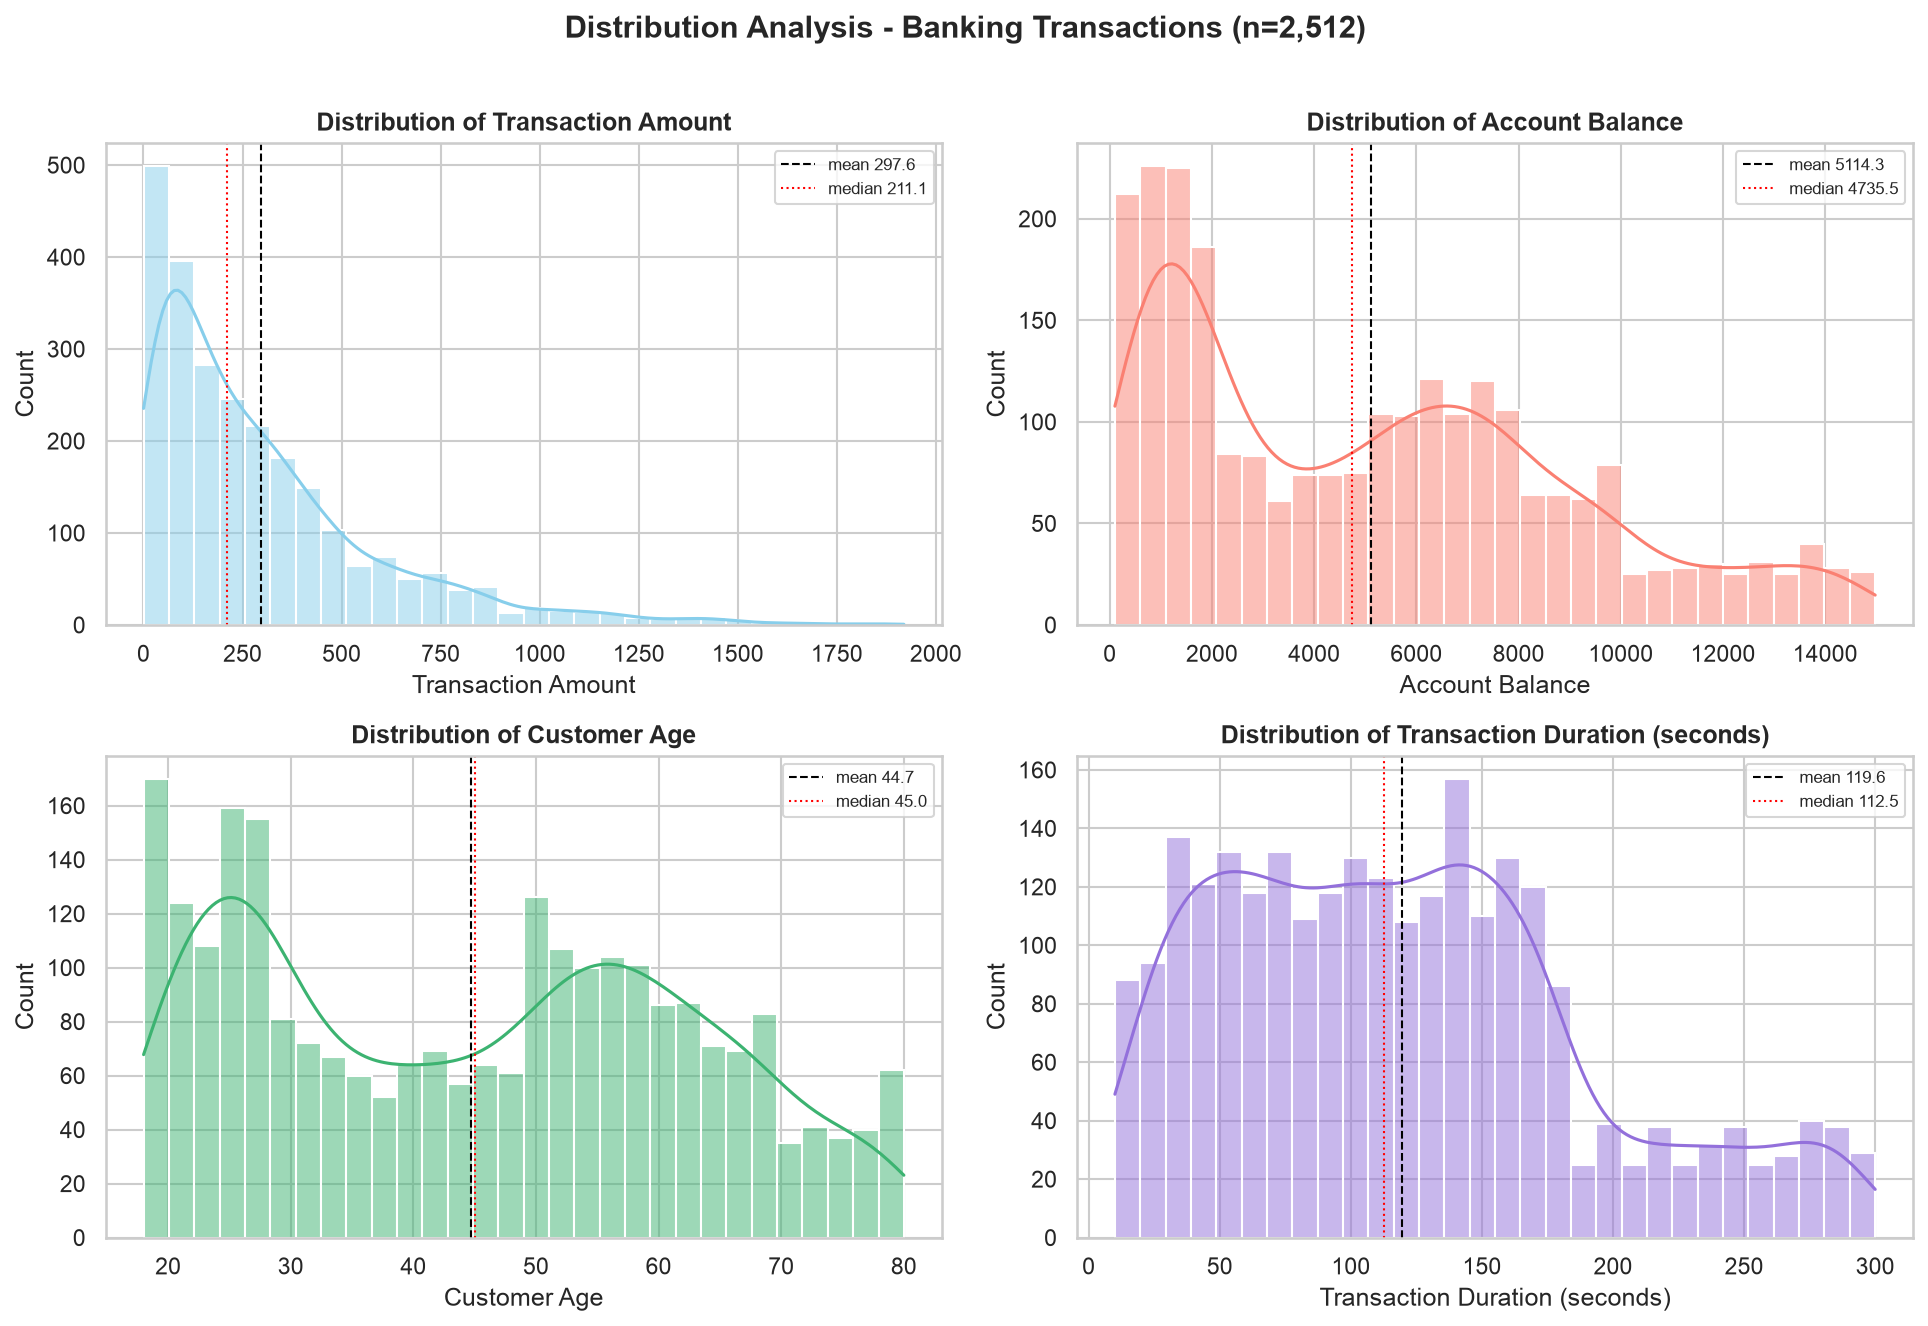

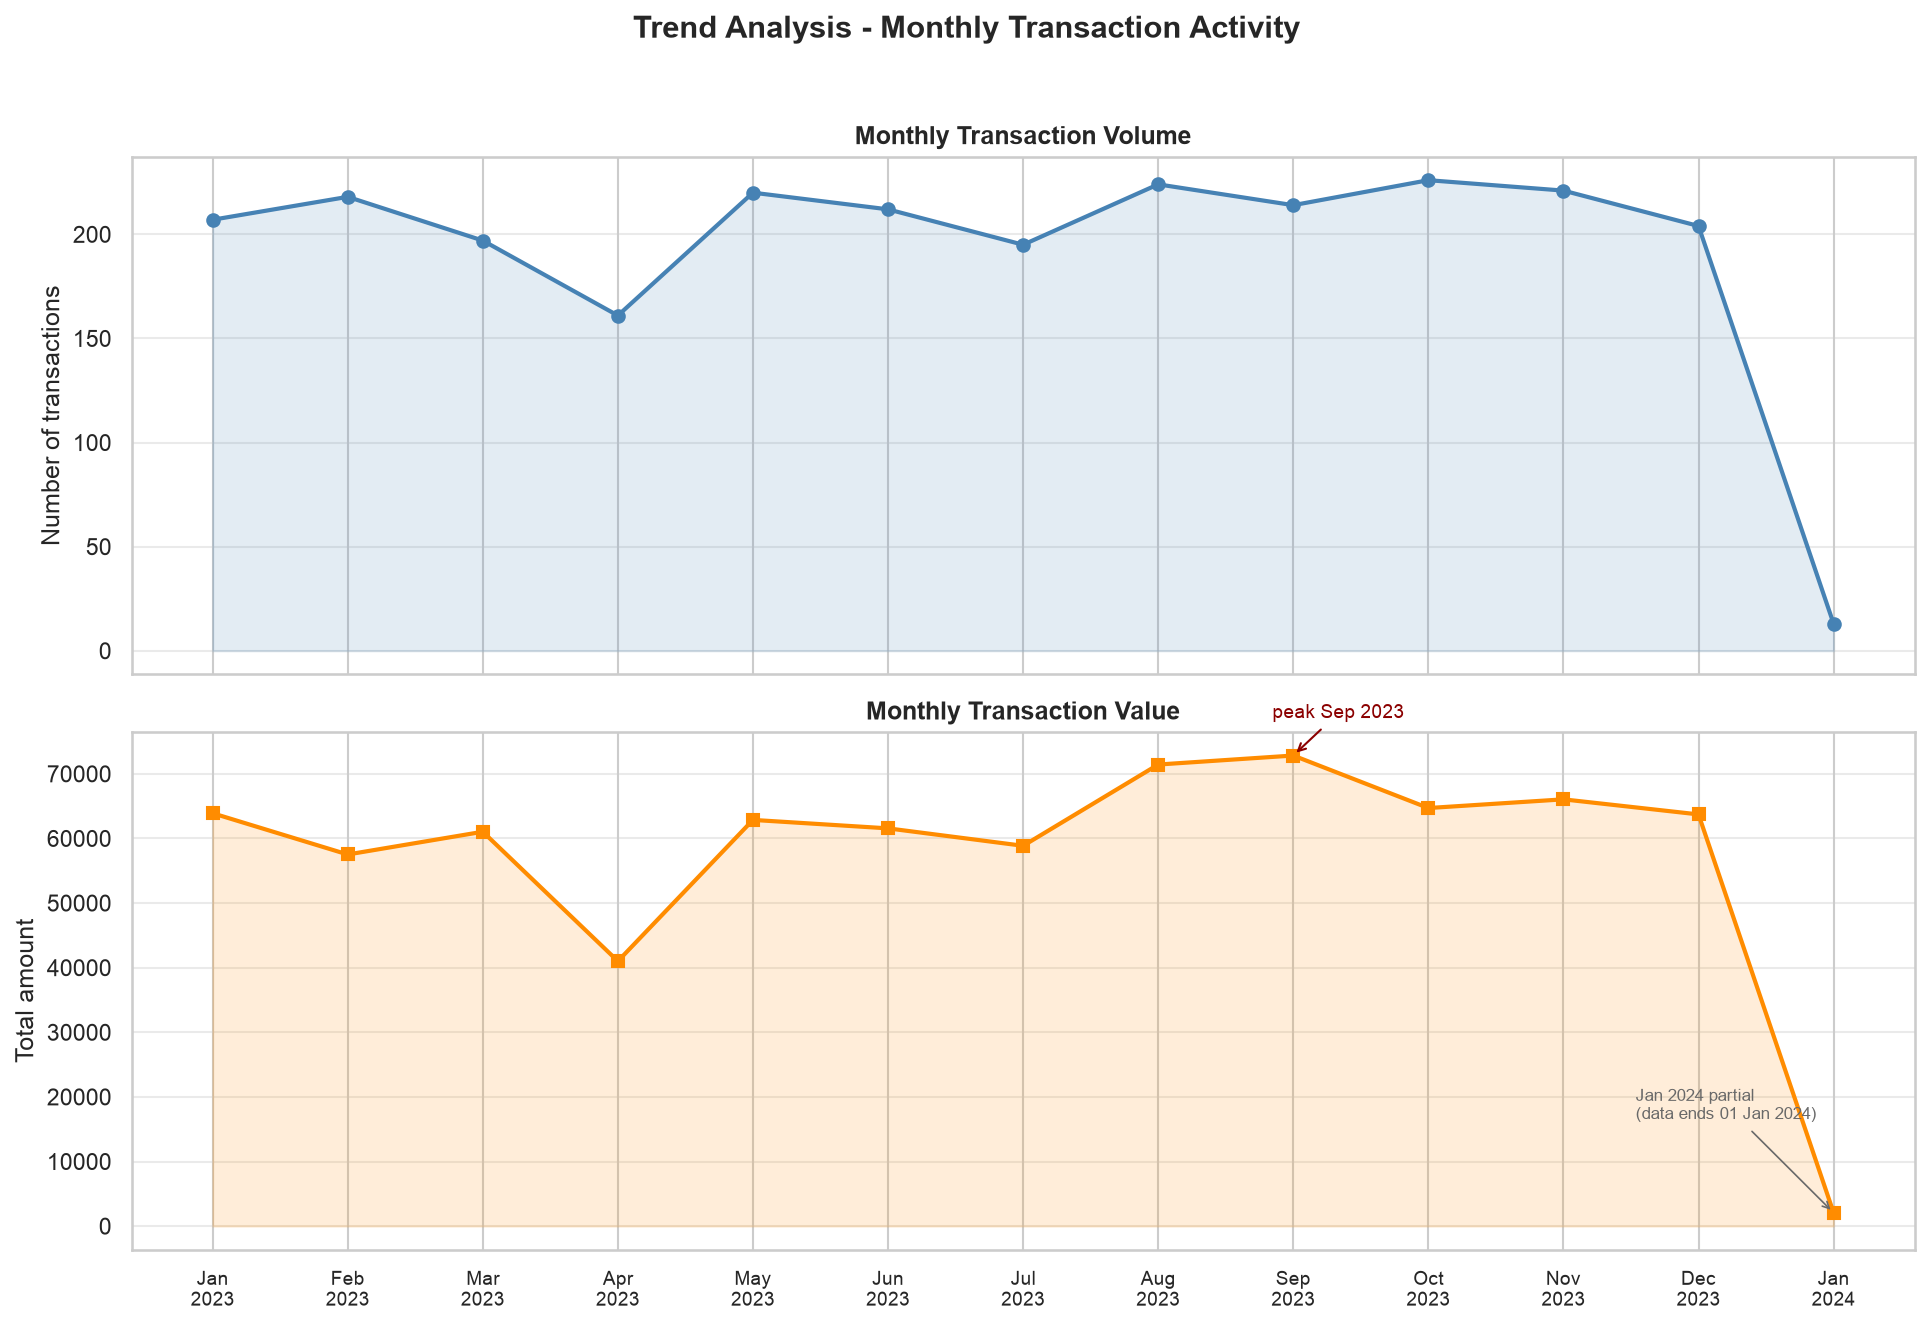

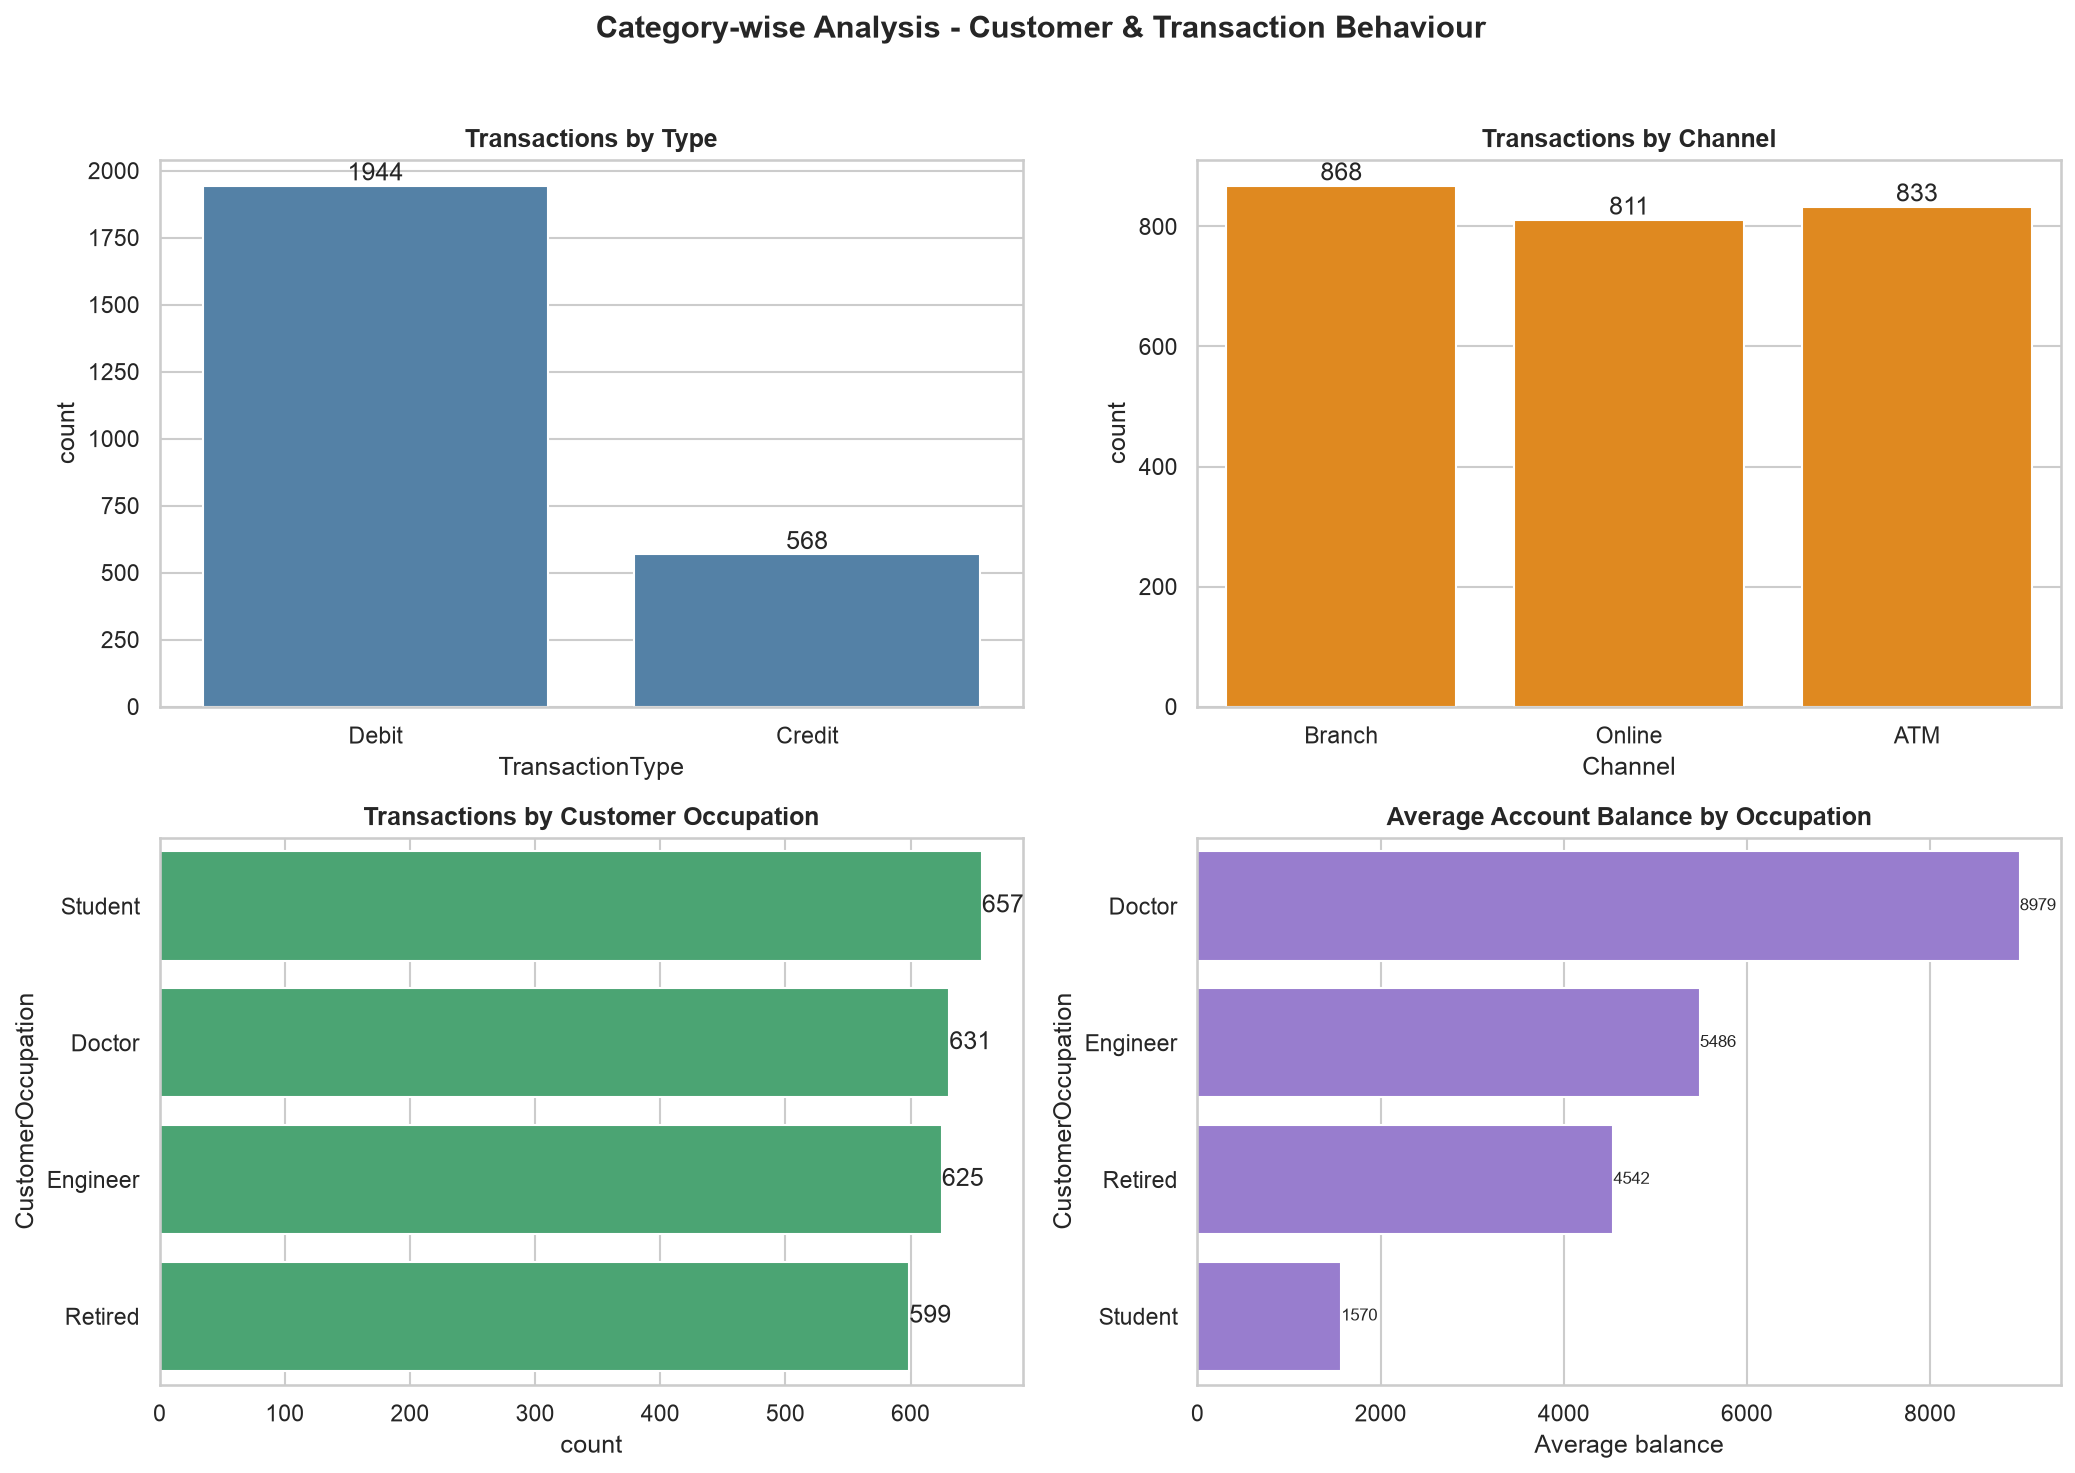

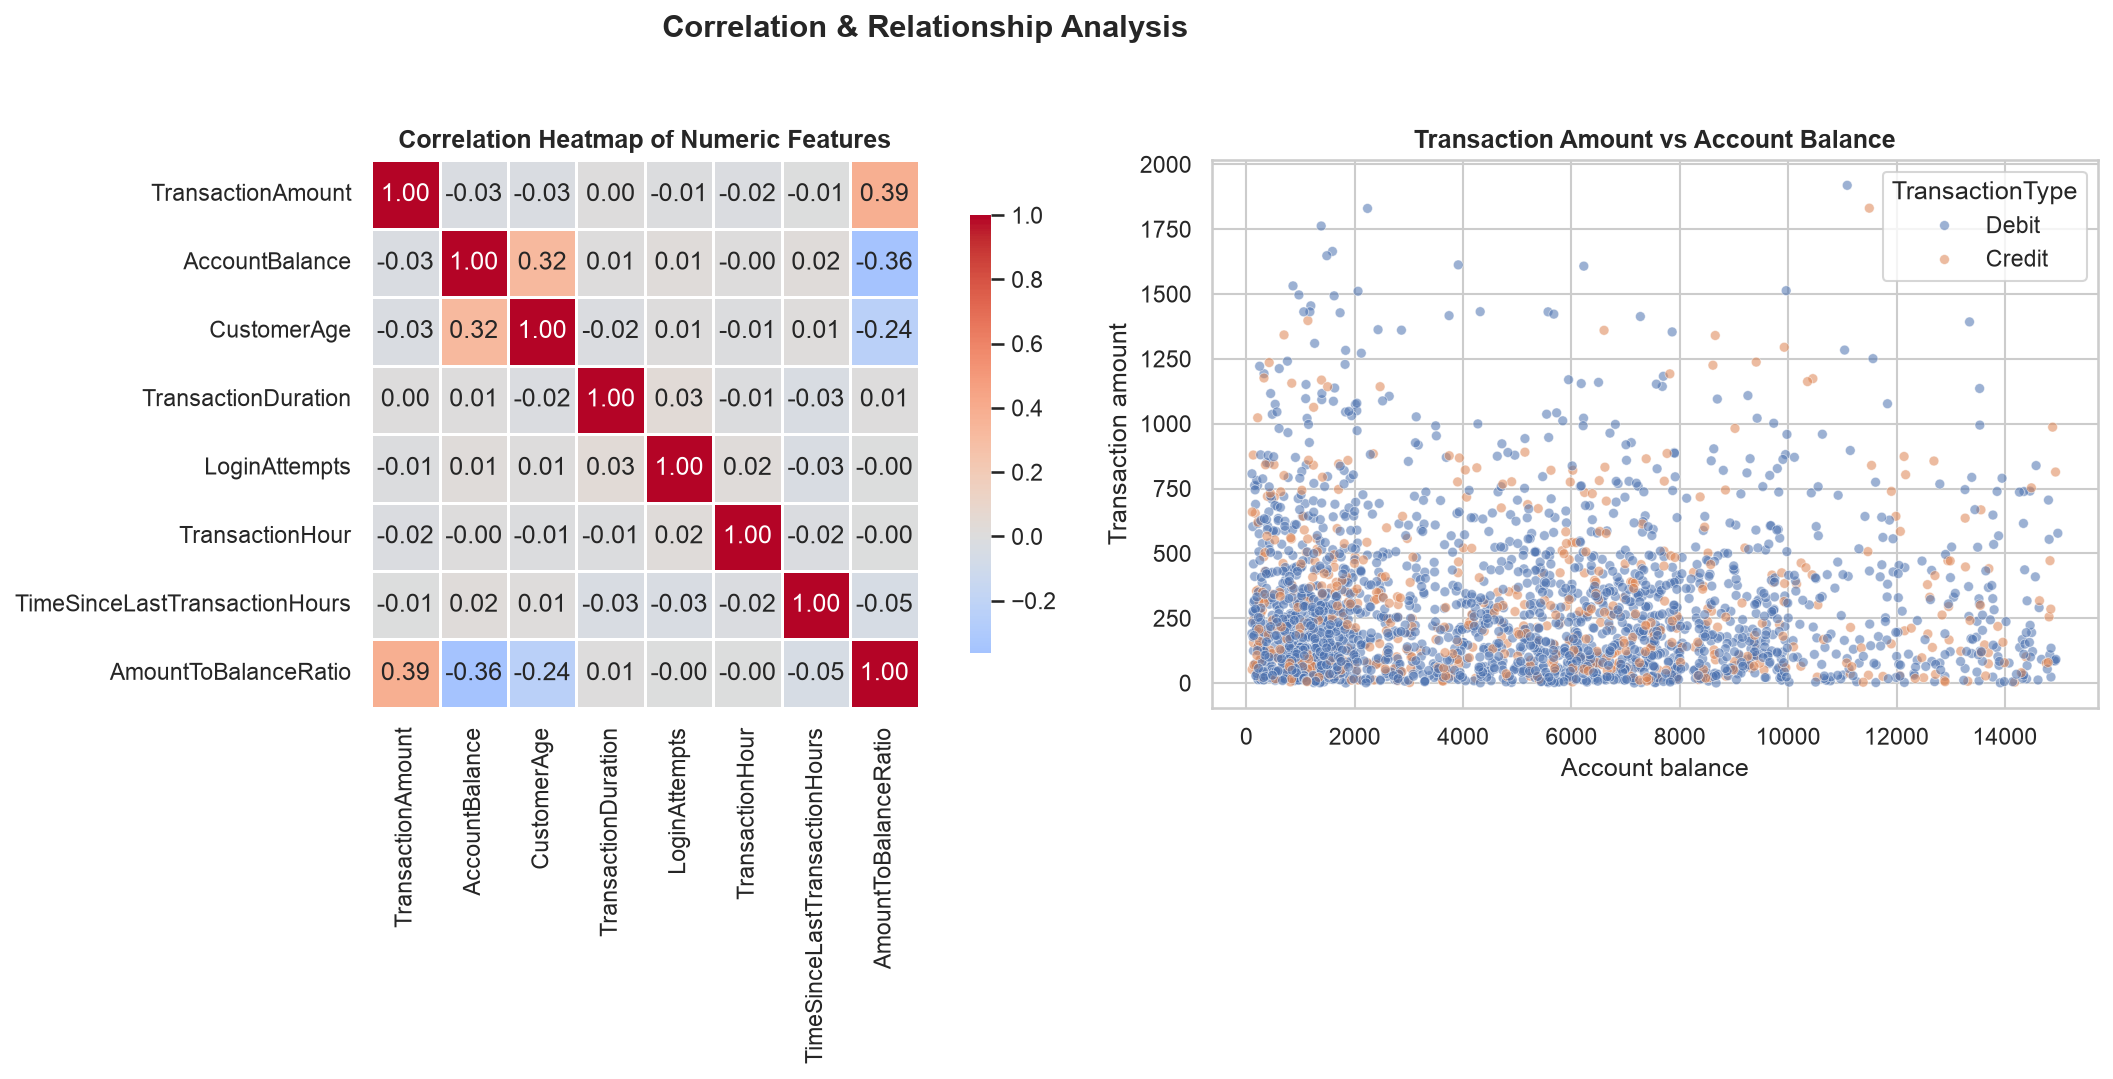

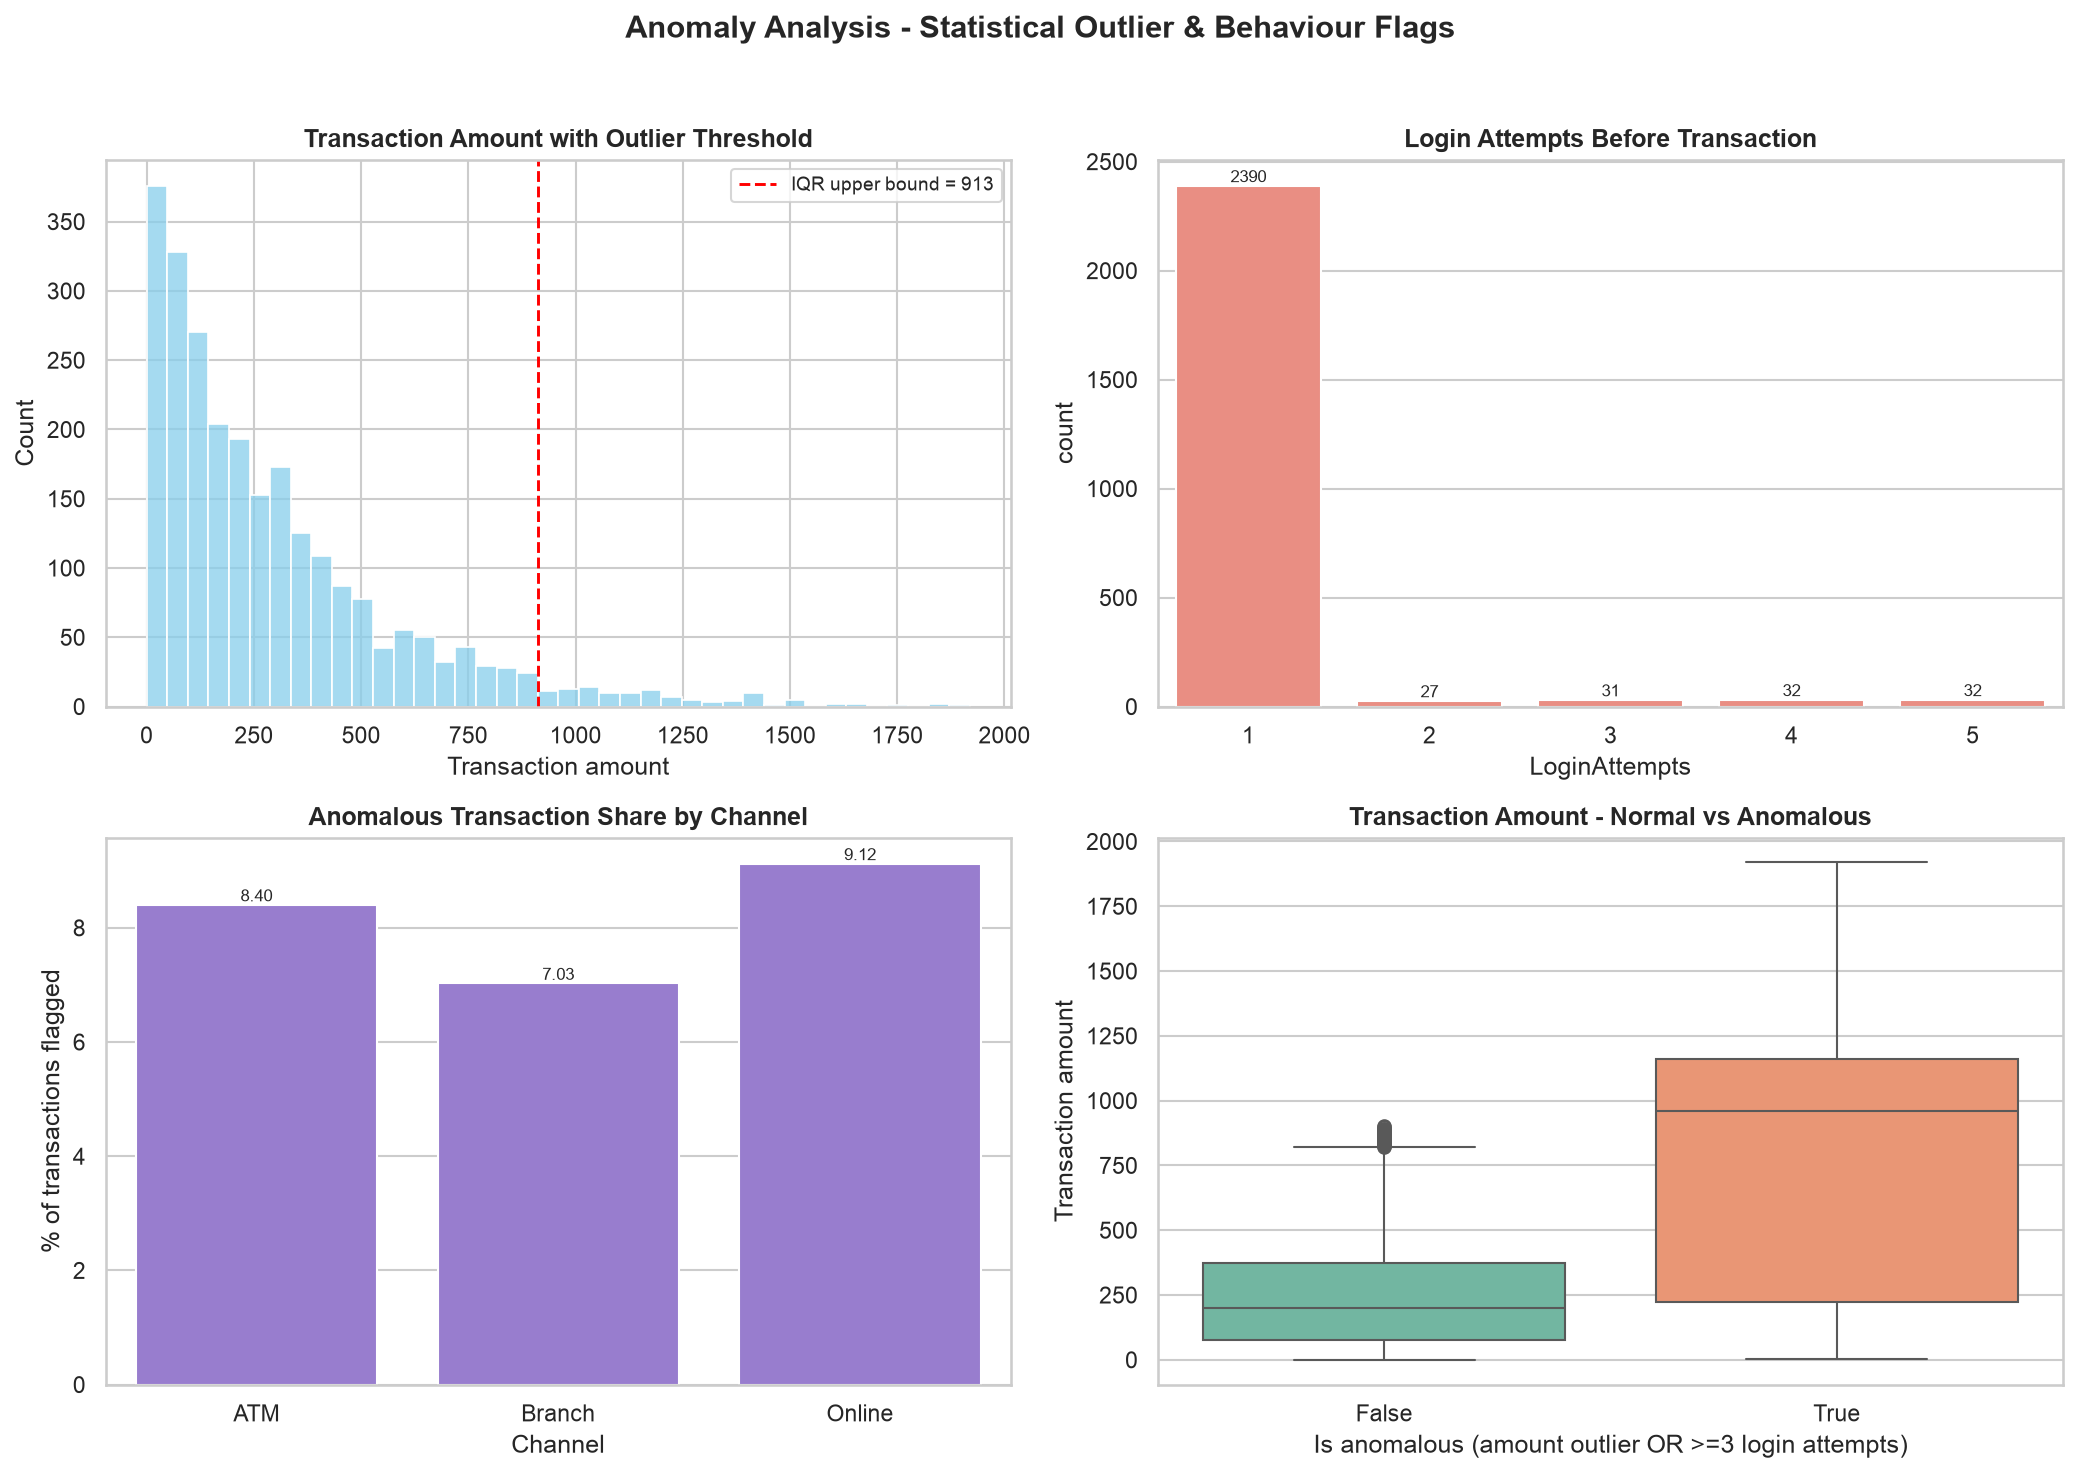

In [14]:
from IPython.display import Image, display
for name in ["distribution_analysis", "trend_analysis", "category_analysis",
             "correlation_analysis", "anomaly_analysis"]:
    display(Image(filename=str(PROJECT_ROOT / "Visualizations" / f"{name}.png")))

## 5. Insights & Recommendations

See `README.md` and `Documentation/Project_Report.md`.